# Task 2 · Wine Quality Prediction
**Objective:** train and compare Random Forest, SGD and SVC classifiers that predict wine quality from physicochemical properties.

**Dataset:** UCI Wine Quality (red wine, *Vinho Verde*), https://archive.ics.uci.edu/dataset/186/wine+quality — 1,599 samples, 11 chemical features, quality score rated 0–10 by tasters.

**Pipeline:** load → EDA → class imbalance → target binning → stratified split → 3 models (tuned with CV) → evaluation → feature importance → comparison → conclusion.

In [1]:
import warnings, os, urllib.request, zipfile, io
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 1. Load the dataset and inspect its structure

In [2]:
# Tries a local copy first, then the UCI repository, then a GitHub mirror.
def load_wine():
    if os.path.exists("data/winequality-red.csv"):
        return pd.read_csv("data/winequality-red.csv", sep=";")
    sources = [
        "https://archive.ics.uci.edu/static/public/186/wine+quality.zip",
        "https://raw.githubusercontent.com/shrikant-temburwar/Wine-Quality-Dataset/master/winequality-red.csv",
    ]
    for url in sources:
        try:
            raw = urllib.request.urlopen(url, timeout=30).read()
            if url.endswith(".zip"):
                with zipfile.ZipFile(io.BytesIO(raw)) as z:
                    return pd.read_csv(z.open("winequality-red.csv"), sep=";")
            return pd.read_csv(io.BytesIO(raw), sep=";")
        except Exception as e:
            print("failed:", url, e)
    raise RuntimeError("Download winequality-red.csv from UCI/Kaggle into ./data/")

df = load_wine()
print("Shape:", df.shape)
df.head()

Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
df.info()
print("\nMissing values:", df.isna().sum().sum(), "| Duplicate rows:", df.duplicated().sum())
df.describe().T.round(3)

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing values: 0 | Duplicate rows: 240


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


,count,percent
quality,,
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


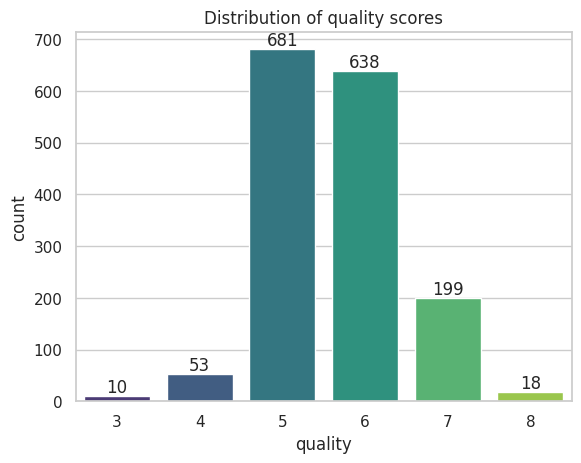

In [4]:
counts = df["quality"].value_counts().sort_index()
pct = (counts / len(df) * 100).round(2)
display(pd.DataFrame({"count": counts, "percent": pct}))

ax = sns.countplot(x="quality", data=df, palette="viridis")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
ax.set_title("Distribution of quality scores"); plt.show()

**Observations.** Scores only range from 3 to 8, and ~82% of wines are rated 5 or 6. Extreme scores (3, 8) have very few examples. The data contains no missing values; duplicate rows exist but are legitimate (different wines can share identical measurements at this precision), so we keep them. (Note: with duplicates a random split can leak near-identical rows into the test set, which slightly flatters tree-based models — worth remembering when reading the results.)

## 2. Exploratory Data Analysis

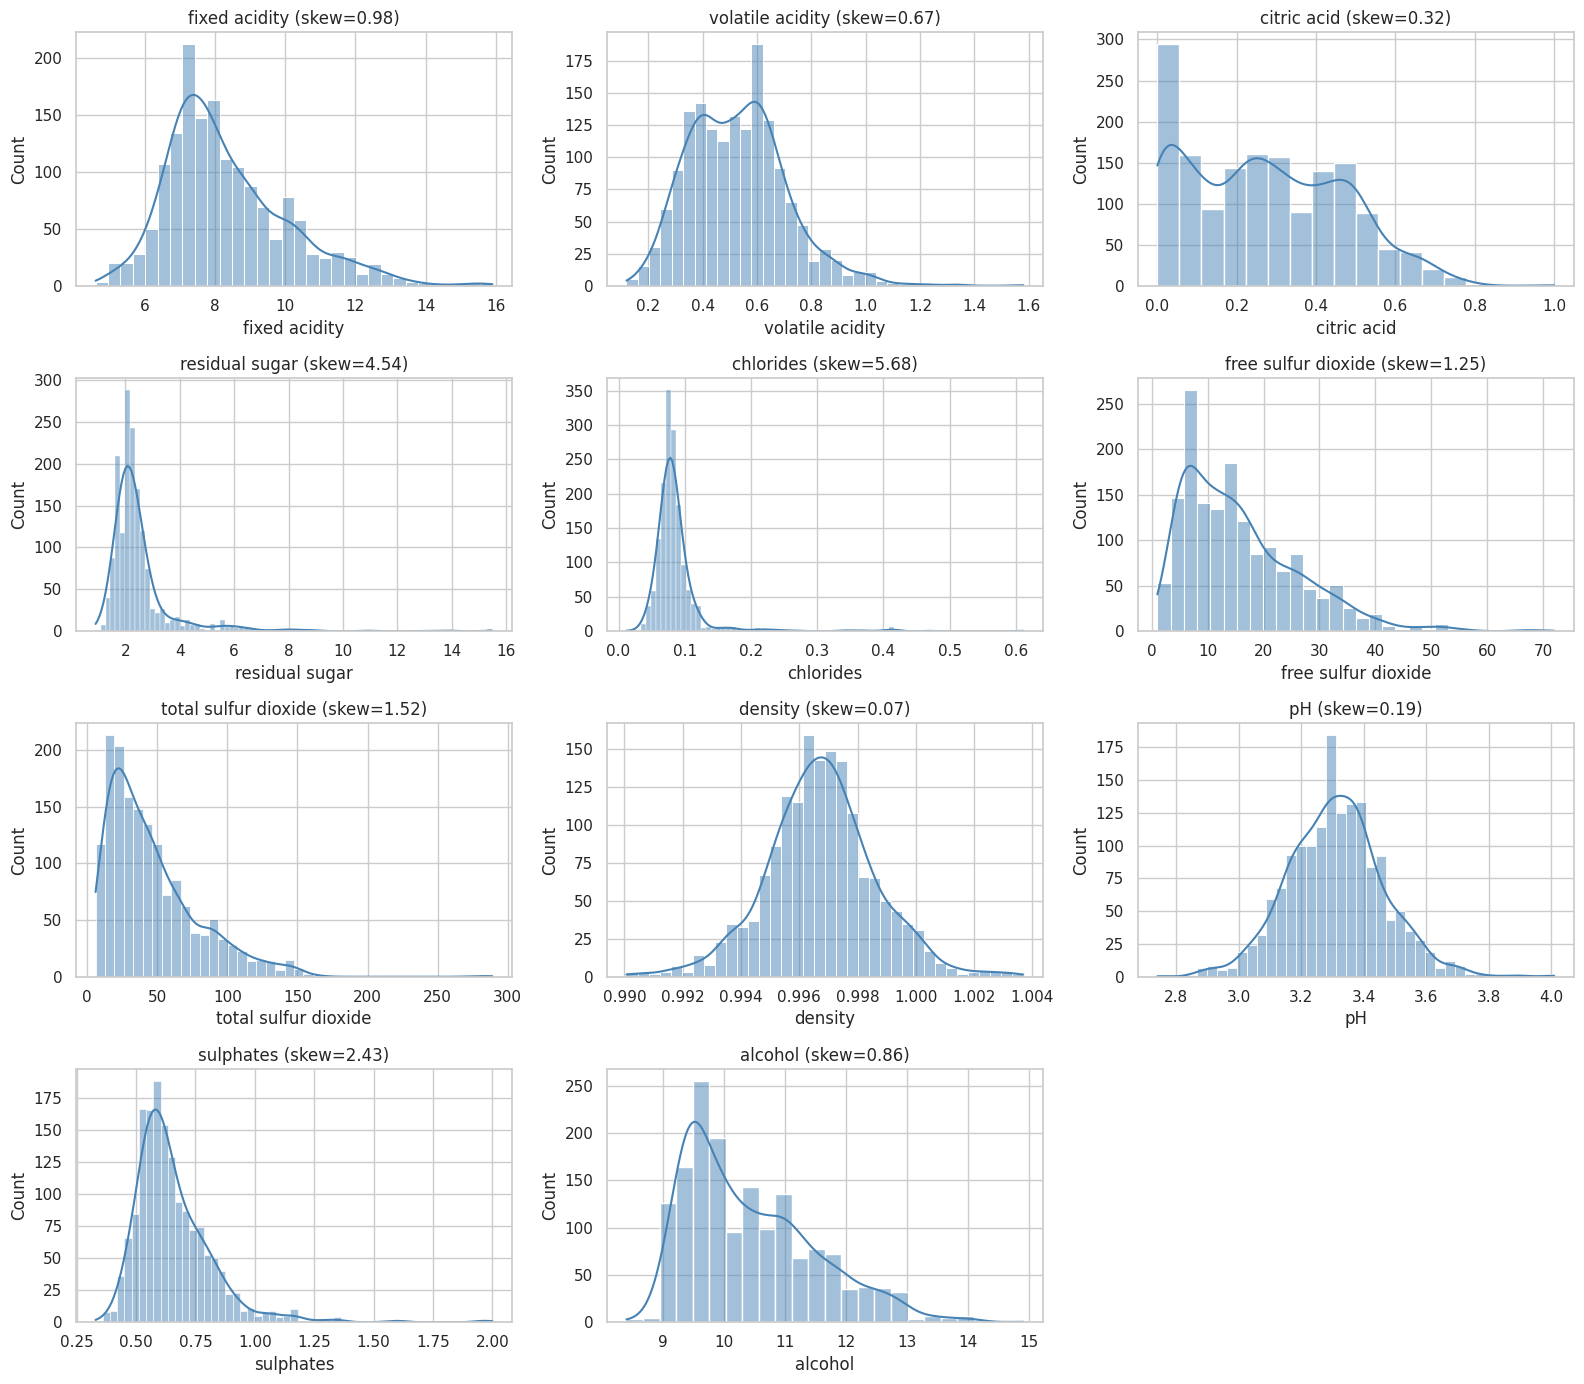

In [5]:
features = [c for c in df.columns if c != "quality"]
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col} (skew={df[col].skew():.2f})")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

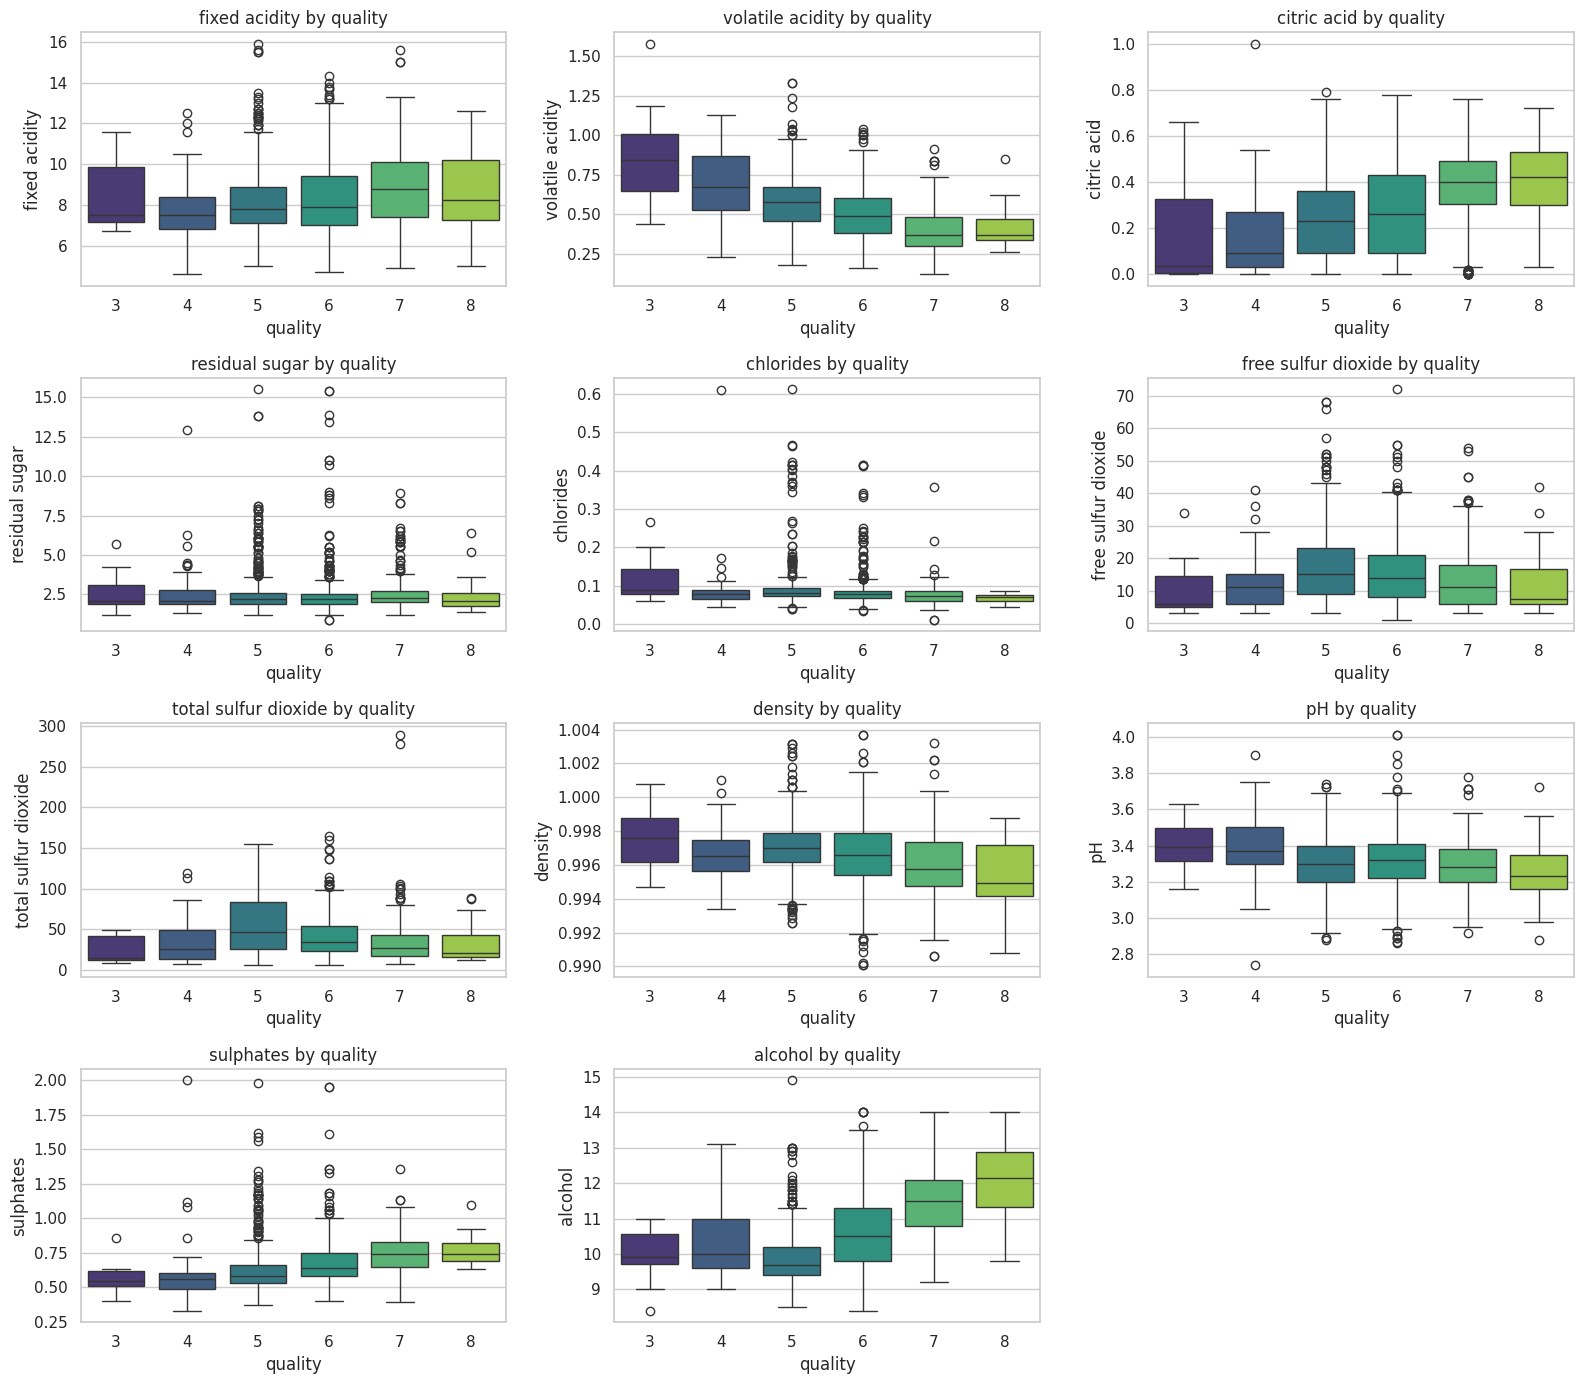

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(x="quality", y=col, data=df, ax=ax, palette="viridis")
    ax.set_title(f"{col} by quality")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

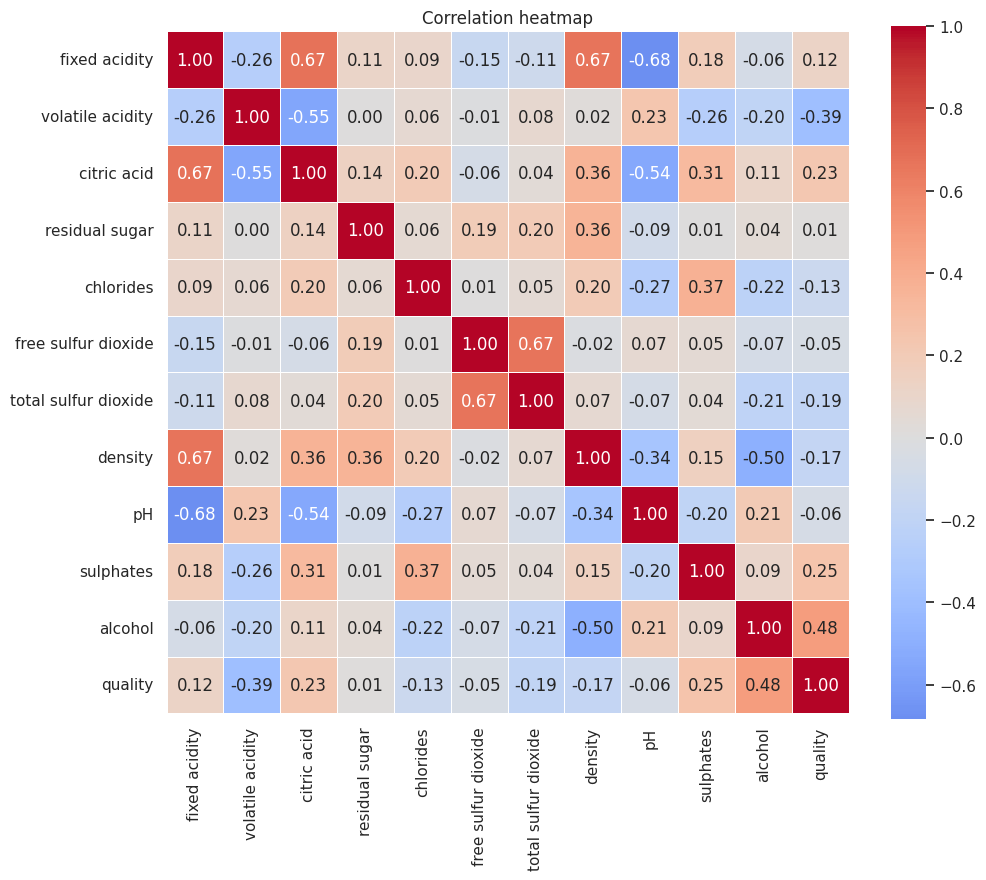

Correlation with quality:
alcohol                 0.476
volatile acidity       -0.391
sulphates               0.251
citric acid             0.226
total sulfur dioxide   -0.185
density                -0.175
chlorides              -0.129
fixed acidity           0.124
pH                     -0.058
free sulfur dioxide    -0.051
residual sugar          0.014
Name: quality, dtype: float64


In [7]:
corr = df.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=.5)
plt.title("Correlation heatmap"); plt.show()

print("Correlation with quality:")
print(corr["quality"].drop("quality").sort_values(key=abs, ascending=False).round(3))

**EDA takeaways**
- Several features (residual sugar, chlorides, sulphates, total SO₂) are strongly **right-skewed with outliers**. Tree models don't care, but SGD/SVC are scale-sensitive, so we standardise features inside a pipeline.
- **Alcohol** has the strongest positive correlation with quality, followed by **sulphates** and **citric acid**; **volatile acidity** is the strongest negative one.
- Multicollinearity exists (fixed acidity ↔ citric acid ↔ density ↔ pH). This doesn't hurt prediction much, but it spreads Random Forest importance across correlated features.
- No single feature separates the classes cleanly (boxplots overlap heavily), so we should expect only moderate accuracy.

## 3. Class imbalance

In [8]:
imb = counts.max() / counts.min()
print(f"Largest/smallest class ratio: {imb:.0f}:1")
print(f"Scores 5 and 6 together: {pct[[5,6]].sum():.1f}% of data")
print(f"Scores 3 and 8 together: {pct[[3,8]].sum():.1f}% of data")

Largest/smallest class ratio: 68:1
Scores 5 and 6 together: 82.5% of data
Scores 3 and 8 together: 1.8% of data


**Does it matter?** Yes — scores 3, 4 and 8 are heavily underrepresented (3 has only 10 samples; the ratio between largest and smallest class is ~68:1). Consequences:
1. **Accuracy becomes misleading.** On the raw scores, always predicting "5" scores ≈43%; after 3-class binning, always predicting "medium" scores ≈82.5%.
2. **Models bias toward the majority classes**; rare classes are rarely predicted and recall for them is near zero.
3. **Stratified splitting is required**, otherwise rare classes may vanish from the test set. With only 10 samples of score 3, even a stratified 20% test set holds 2 examples → per-class metrics are extremely noisy.

**Mitigations used here:** (a) bin the target (next section), (b) stratified split, (c) `class_weight="balanced"`, (d) judge models by **macro-F1** and per-class recall, not accuracy alone.

## 4. Feature engineering: binning the target

In [9]:
# Baseline on the raw 6-class target to justify binning
X = df[features]
y_raw = df["quality"]
Xtr, Xte, ytr, yte = train_test_split(X, y_raw, test_size=0.2, stratify=y_raw, random_state=RANDOM_STATE)
rf_raw = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE).fit(Xtr, ytr)
p = rf_raw.predict(Xte)
print(f"Raw 6-class RF  -> accuracy {accuracy_score(yte,p):.3f}, macro-F1 {f1_score(yte,p,average='macro'):.3f}")
print(classification_report(yte, p, zero_division=0))

Raw 6-class RF  -> accuracy 0.675, macro-F1 0.415
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.72      0.75      0.74       136
           6       0.62      0.73      0.67       128
           7       0.76      0.47      0.58        40
           8       1.00      0.33      0.50         3

    accuracy                           0.68       320
   macro avg       0.52      0.38      0.42       320
weighted avg       0.66      0.68      0.66       320



In [10]:
# Two candidate binning schemes
def to_3class(q):  return "low" if q <= 4 else ("medium" if q <= 6 else "high")
def to_binary(q):  return "good" if q >= 7 else "bad"

df["quality_3c"] = df["quality"].apply(to_3class)
df["quality_bin"] = df["quality"].apply(to_binary)
pd.concat([df["quality_3c"].value_counts().rename("3-class"),
           df["quality_bin"].value_counts().rename("binary")], axis=1)

,3-class,binary
medium,1319.0,NaN
high,217.0,NaN
low,63.0,NaN
bad,NaN,1382.0
good,NaN,217.0


**Decision: use 3-class (low: 3–4, medium: 5–6, high: 7–8) as the main target.**

Why bin at all? The raw 6-class model performs poorly (see macro-F1 above): neighbouring scores like 5 vs 6 are separated by taster subjectivity rather than by measurable chemistry, and the rarest scores have too few samples to learn from.

Why 3-class rather than binary?
- *Binary (good ≥ 7)* is simplest but collapses 86% of wines into "bad", merging genuinely poor wines (score 3–4) with decent ones (5–6), which loses useful information.
- *3-class* keeps a meaningful business interpretation (reject / standard / premium) and gives the models a harder, more informative task. Its cost is that "low" is still small (~4%), so we rely on class weights and macro-F1.

The code is written so the binary scheme can be switched on by changing `TARGET` below.

## 5. Stratified train/test split

In [11]:
TARGET = "quality_3c"          # or "quality_bin"
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

labels = ["low", "medium", "high"] if TARGET == "quality_3c" else ["bad", "good"]
split = pd.DataFrame({"train %": y_train.value_counts(normalize=True)*100,
                      "test %":  y_test.value_counts(normalize=True)*100,
                      "train n": y_train.value_counts(), "test n": y_test.value_counts()}).loc[labels].round(2)
split

,train %,test %,train n,test n
quality_3c,,,,
low,3.91,4.06,50,13
medium,82.49,82.50,1055,264
high,13.60,13.44,174,43


## 6. Train the three classifiers
Each model is wrapped in a `Pipeline` (so scaling is fit only on training folds — no leakage) and tuned with 5-fold stratified `GridSearchCV` optimising **macro-F1**. All use `class_weight='balanced'`.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Random Forest": (
        Pipeline([("scale", StandardScaler()),
                  ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))]),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 15], "clf__min_samples_leaf": [1, 2]}),
    "SGD": (
        Pipeline([("scale", StandardScaler()),
                  ("clf", SGDClassifier(class_weight="balanced", max_iter=2000, tol=1e-3, random_state=RANDOM_STATE))]),
        {"clf__loss": ["hinge", "log_loss", "modified_huber"], "clf__alpha": [1e-4, 1e-3, 1e-2],
         "clf__penalty": ["l2", "elasticnet"]}),
    "SVC": (
        Pipeline([("scale", StandardScaler()),
                  ("clf", SVC(class_weight="balanced", random_state=RANDOM_STATE))]),
        {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1], "clf__kernel": ["rbf"]}),
}

fitted = {}
for name, (pipe, grid) in candidates.items():
    gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=cv, n_jobs=-1).fit(X_train, y_train)
    fitted[name] = gs
    print(f"{name:14s} best CV macro-F1 = {gs.best_score_:.3f} | {gs.best_params_}")

Random Forest  best CV macro-F1 = 0.537 | {'clf__max_depth': 15, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 400}


SGD            best CV macro-F1 = 0.553 | {'clf__alpha': 0.01, 'clf__loss': 'log_loss', 'clf__penalty': 'elasticnet'}


SVC            best CV macro-F1 = 0.583 | {'clf__C': 100, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}


## 7. Evaluation: accuracy, classification report, confusion matrix

Random Forest  |  test accuracy = 0.856
              precision    recall  f1-score   support

         low       0.00      0.00      0.00        13
      medium       0.89      0.94      0.91       264
        high       0.63      0.63      0.63        43

    accuracy                           0.86       320
   macro avg       0.51      0.52      0.51       320
weighted avg       0.82      0.86      0.84       320

SGD  |  test accuracy = 0.794
              precision    recall  f1-score   support

         low       0.00      0.00      0.00        13
      medium       0.88      0.88      0.88       264
        high       0.47      0.49      0.48        43

    accuracy                           0.79       320
   macro avg       0.45      0.46      0.45       320
weighted avg       0.79      0.79      0.79       320

SVC  |  test accuracy = 0.816
              precision    recall  f1-score   support

         low       0.17      0.15      0.16        13
      medium       0.91      

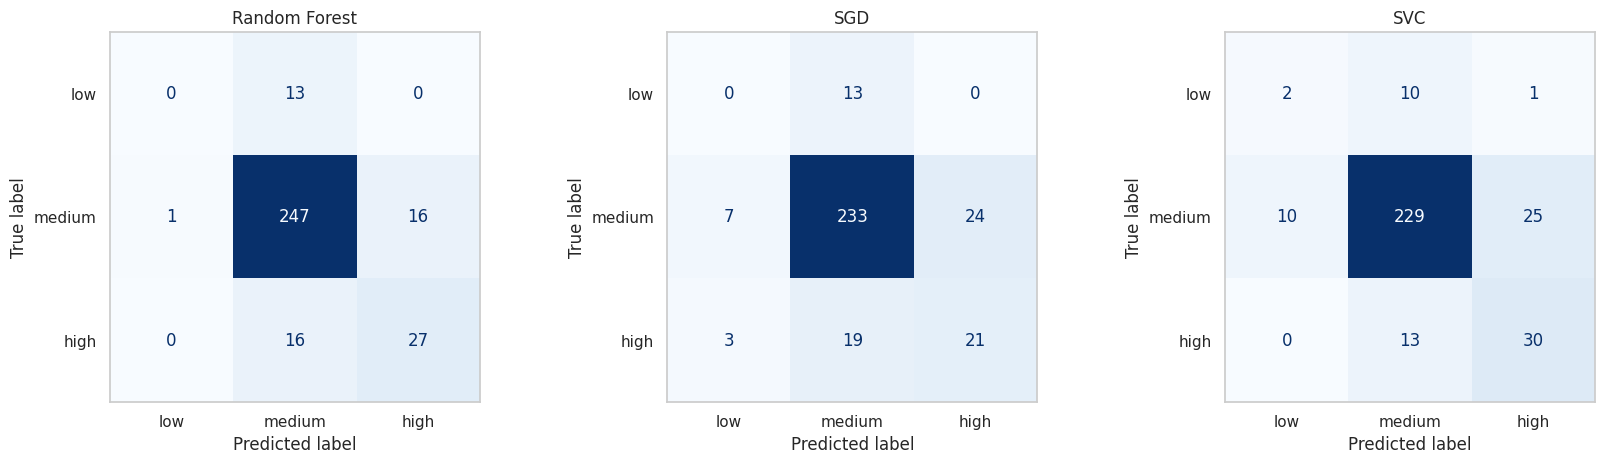

In [13]:
results, preds = [], {}
for name, gs in fitted.items():
    y_pred = gs.predict(X_test); preds[name] = y_pred
    print("="*70, f"\n{name}  |  test accuracy = {accuracy_score(y_test, y_pred):.3f}\n", "="*70, sep="")
    print(classification_report(y_test, y_pred, labels=labels, zero_division=0))
    results.append({"Model": name,
        "CV macro-F1": gs.best_score_,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Weighted F1": f1_score(y_test, y_pred, average="weighted"),
        **{f"Recall ({l})": (y_pred[(y_test==l).values] == l).mean() for l in labels}})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.show()

## 8. Random Forest feature importance

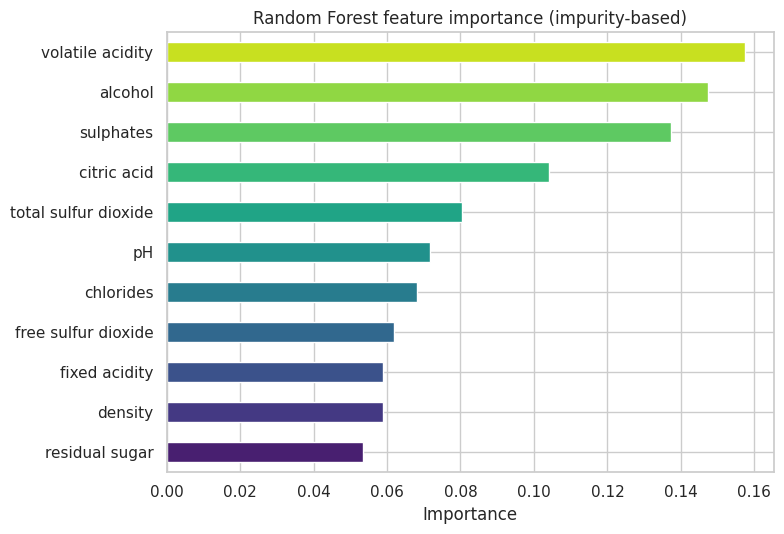

volatile acidity        0.157
alcohol                 0.147
sulphates               0.137
citric acid             0.104
total sulfur dioxide    0.080
pH                      0.072
chlorides               0.068
free sulfur dioxide     0.062
fixed acidity           0.059
density                 0.059
residual sugar          0.054
dtype: float64

In [14]:
rf = fitted["Random Forest"].best_estimator_.named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
plt.figure(figsize=(8, 5.5))
imp.plot(kind="barh", color=sns.color_palette("viridis", len(imp)))
plt.title("Random Forest feature importance (impurity-based)"); plt.xlabel("Importance"); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(3)

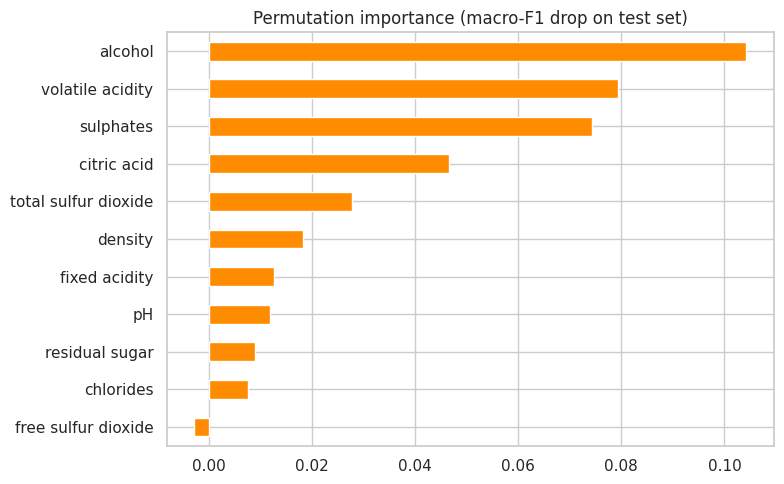

In [15]:
# Permutation importance on the test set is less biased toward high-cardinality / correlated features
from sklearn.inspection import permutation_importance
pi = permutation_importance(fitted["Random Forest"].best_estimator_, X_test, y_test,
                            scoring="f1_macro", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(pi.importances_mean, index=features).sort_values().plot(kind="barh", figsize=(8,5), color="darkorange")
plt.title("Permutation importance (macro-F1 drop on test set)"); plt.tight_layout(); plt.show()

## 9. Model comparison

Majority-class baseline accuracy (always predict the most common class): 0.825



,CV macro-F1,Accuracy,Macro F1,Weighted F1,Recall (low),Recall (medium),Recall (high)
Model,,,,,,,
Random Forest,0.537000,0.856000,0.514000,0.839000,0.000000,0.936000,0.628000
SGD,0.553000,0.794000,0.453000,0.791000,0.000000,0.883000,0.488000
SVC,0.583000,0.816000,0.551000,0.820000,0.154000,0.867000,0.698000


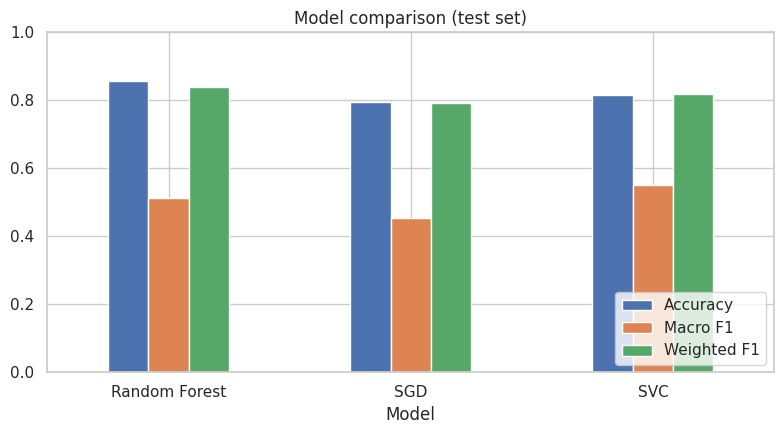

In [16]:
baseline = y_test.value_counts(normalize=True).max()
print(f"Majority-class baseline accuracy (always predict the most common class): {baseline:.3f}")
print()
comparison = pd.DataFrame(results).set_index("Model").round(3)
display(comparison.style.highlight_max(axis=0, color="#c6efce"))

comparison[["Accuracy", "Macro F1", "Weighted F1"]].plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.ylim(0, 1); plt.title("Model comparison (test set)"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 10. Conclusion

### Results summary (test set, 320 wines, 3-class target)

| Model | Accuracy | Macro-F1 | CV macro-F1 | Recall: low / medium / high |
|---|---|---|---|---|
| Random Forest | 0.856 | 0.51 | 0.537 | 0.00 / 0.94 / 0.63 |
| SGD | 0.794 | 0.45 | 0.553 | 0.00 / 0.88 / 0.49 |
| SVC (RBF) | 0.816 | 0.55 | 0.583 | 0.15 / 0.87 / 0.70 |

*(Exact figures are in the comparison table above; re-running with a different seed may shift them slightly.)*

**Key point on accuracy:** 82.5% of wines are "medium", so a model that always predicts "medium" already scores ~82.5% accuracy. Random Forest's 85.6% is therefore only a modest gain, and SGD (79.4%) is actually *below* that trivial baseline. Macro-F1 and minority-class recall are the more honest yardsticks here.

**Findings**
- **Random Forest** has the highest accuracy and the best precision on "high" quality wines, but it never identifies a "low" wine and has the lowest cross-validated macro-F1 of the tuned non-linear models.
- **SVC (RBF)** has the best macro-F1 in both cross-validation (0.583) and on the test set, the highest recall for premium wines (70%), and is the only model that detects any "low" wines. It trades a few points of accuracy for this.
- **SGD** (a linear model) is the weakest: the relationship between chemistry and quality is non-linear, and a linear boundary can't capture it. It is fast and easy to retrain, but not accurate enough here.
- **Drivers of quality** (RF importance): volatile acidity, alcohol and sulphates lead, followed by citric acid and total SO₂. This matches the EDA correlations and is chemically sensible (high volatile acidity → vinegar taste; higher alcohol → fuller body).

### Recommendation: SVC for deployment (Random Forest as the close alternative)
SVC is the most suitable choice if the aim is to **flag wines at the quality extremes** (reject or promote), because it has the best macro-F1, the best recall on premium wines and the only non-zero recall on poor wines, and its advantage is visible in cross-validation (1,279 training rows), not only in the small test set. Random Forest is preferable if overall accuracy and interpretability matter most: it needs no feature scaling, is robust to outliers and skew, and directly provides feature importances to explain predictions to winemakers.

### Limitations and next steps
- **Moderate performance overall.** Quality is a subjective taster score; chemistry explains only part of it. The "low" class (63 wines, 13 in the test set) is too small for reliable conclusions: SVC's 0.15 recall is 2 wines out of 13, so differences between models on that class are within noise.
- Only the **red wine** file was used. Adding the white wine file (4,898 samples) would give far more data, especially for rare classes.
- Improvements to try: SMOTE/oversampling inside CV, threshold tuning for the minority classes, gradient boosting (XGBoost/LightGBM), feature transformations for skewed variables, and repeated/nested CV for tighter confidence intervals.
- Because the data contains duplicate rows, the random split may slightly inflate scores, especially for Random Forest.